In [ ]:
!pip install ucimlrepo
!pip install keras-tuner
!pip install scikeras

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold, cross_val_predict
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    confusion_matrix, classification_report, roc_curve, auc
)

import keras
from keras.models import Sequential
from keras.layers import Dense, Input, Dropout
from keras.callbacks import EarlyStopping

import keras_tuner as kt


In [ ]:
# ============================================================
# FASE 2 — Cargar datos desde UCIMLrepo
# ============================================================

from ucimlrepo import fetch_ucirepo
data = fetch_ucirepo(id=426)

df = pd.concat([data.data.features, data.data.targets], axis=1)

print("Columnas originales:")
print(df.columns)

Columnas originales:
Index(['A1_Score', 'A2_Score', 'A3_Score', 'A4_Score', 'A5_Score', 'A6_Score',
       'A7_Score', 'A8_Score', 'A9_Score', 'A10_Score', 'age', 'gender',
       'ethnicity', 'jaundice', 'family_pdd', 'country_of_res',
       'used_app_before', 'result', 'age_desc', 'relation', 'class'],
      dtype='object')


In [ ]:
# ============================================================
# FASE 3 — Limpieza inicial
# ============================================================

df = df.drop_duplicates()                  # borrar duplicados
df = df[df["age"] <= 120]                  # quitar edades irreales
df = df.dropna()                           # quitar filas incompletas

print("Shape tras limpieza:", df.shape)



Shape tras limpieza: (603, 21)


In [ ]:
# ============================================================
# FASE 4 — Separar numéricas y categóricas
# ============================================================

categorical_cols = ['gender', 'ethnicity', 'jaundice', 'family_pdd',
                    'country_of_res', 'used_app_before', 'age_desc',
                    'relation', 'class']

numeric_cols = ['A1_Score','A2_Score','A3_Score','A4_Score','A5_Score',
                'A6_Score','A7_Score','A8_Score','A9_Score','A10_Score',
                'age','result']



In [ ]:
# ============================================================
# FASE 5 — One-hot encoding
# ============================================================

ohe = OneHotEncoder(drop="first", sparse_output=False)

preprocessor = ColumnTransformer([
    ("cat", ohe, categorical_cols),
    ("num", "passthrough", numeric_cols)
])

df_encoded = preprocessor.fit_transform(df)
df_encoded = pd.DataFrame(df_encoded)

# Obtener nombre de todas las columnas codificadas
encoded_cols = list(preprocessor.get_feature_names_out())

df_encoded.columns = encoded_cols

# Columna objetivo
target_col = [c for c in df_encoded.columns if "class_" in c][0]

X = df_encoded.drop(columns=[target_col])
y = df_encoded[target_col]

print("Target detectado:", target_col)
print("X shape:", X.shape)
print("y shape:", y.shape)


Target detectado: cat__class_YES
X shape: (603, 89)
y shape: (603,)


In [ ]:
# ============================================================
# FASE 6 — Train test split 80/20 + Normalización
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test  = scaler.transform(X_test)

In [ ]:
# ============================================================
# FUNCIONES AUXILIARES PARA GRAFICOS
# ============================================================

def plot_confusion_matrix(cm, title):
    plt.figure(figsize=(5,4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
    plt.title(title)
    plt.xlabel("Predicción")
    plt.ylabel("Real")
    plt.show()


def compute_metrics(cm):
    TN, FP, FN, TP = cm.ravel()
    acc = (TP+TN)/(TP+TN+FP+FN)
    sens = TP/(TP+FN)
    esp = TN/(TN+FP)
    vpp = TP/(TP+FP)
    vpn = TN/(TN+FN)
    return acc, sens, esp, vpp, vpn


def plot_roc_curve(y_true, y_prob, title):
    fpr, tpr, _ = roc_curve(y_true, y_prob)
    curve_auc = auc(fpr, tpr)

    plt.figure(figsize=(5,4))
    plt.plot(fpr, tpr, label=f"AUC = {curve_auc:.3f}")
    plt.plot([0,1],[0,1],"--")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(title)
    plt.legend()
    plt.show()


def plot_history(history, title):
    plt.figure(figsize=(10,4))

    plt.subplot(1,2,1)
    plt.plot(history.history["loss"])
    plt.plot(history.history["val_loss"])
    plt.title(f"{title} - Loss")
    plt.legend(["Train","Validation"])

    plt.subplot(1,2,2)
    plt.plot(history.history["accuracy"])
    plt.plot(history.history["val_accuracy"])
    plt.title(f"{title} - Accuracy")
    plt.legend(["Train","Validation"])

    plt.show()





4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step


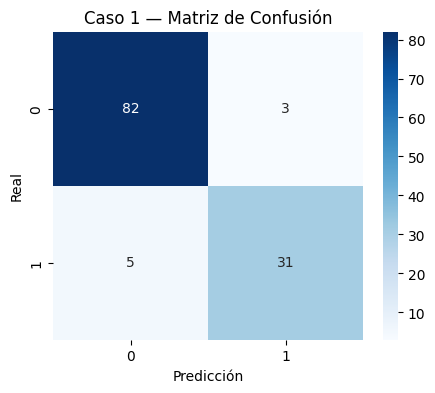

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step


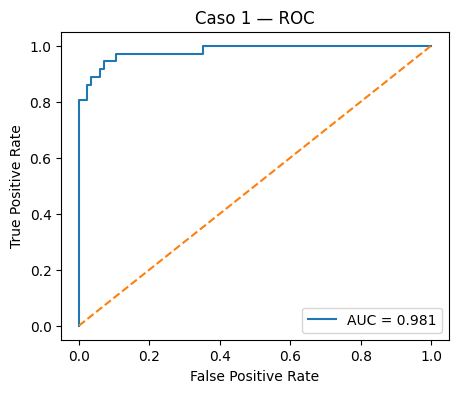

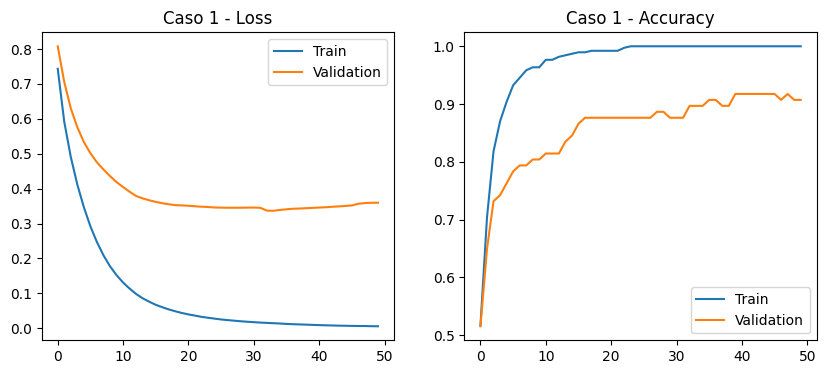

In [ ]:
#  CASO 1 Modelo raw

model1 = Sequential([
    Input(shape=(X_train.shape[1],)), # establece numero de atributos entrantes
    Dense(32, activation="relu"),
    Dense(16, activation="relu"),    #{ capas ocultas de 32 y 16 neuronas para aprendizaje y control de sesgos
    Dense(1, activation="sigmoid")   # Capa de salida para clasificacion
])

model1.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"]) # uso de asistente inteligente Adam y funcion de pérdida binaria

history1 = model1.fit(
    X_train, y_train,
    epochs=50, batch_size=32,  #{ Entrenamiento con 50 ciclos y aplicacion del 20% de validación
    validation_split=0.2,
    verbose=0
)

y_pred1 = (model1.predict(X_test) > 0.5).astype(int)
cm1 = confusion_matrix(y_test, y_pred1)

# Graficos
plot_confusion_matrix(cm1, "Caso 1 — Matriz de Confusión")
acc1, sens1, esp1, vpp1, vpn1 = compute_metrics(cm1)
plot_roc_curve(y_test, model1.predict(X_test), "Caso 1 — ROC")
plot_history(history1, "Caso 1")


4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step


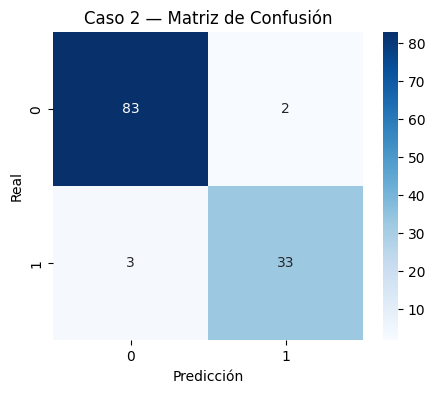

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 


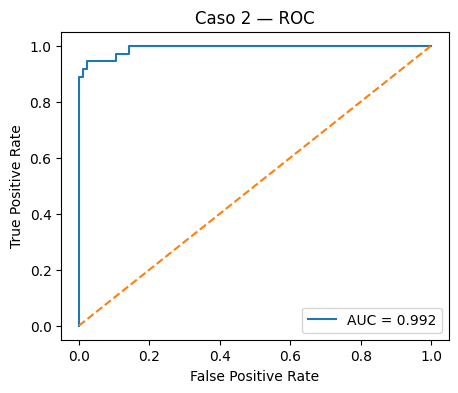

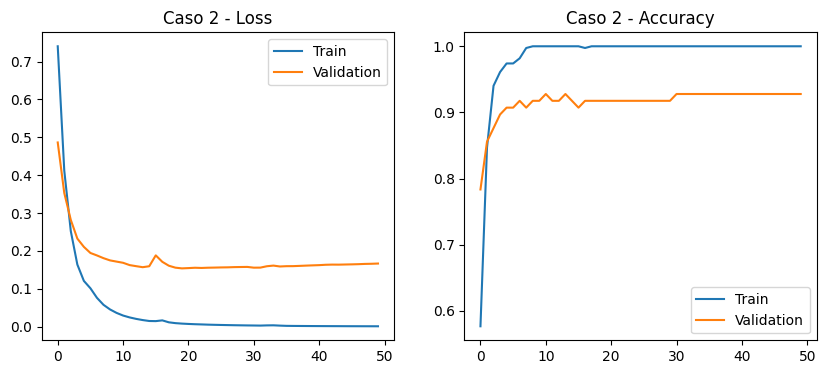

In [ ]:
# CASO 2: Optimización de hiperparámetros

def build_model(hp):                                                      # Modelo principal, permite que Keras-tuner pruebe diferentes hiperparámetros
    neurons = hp.Int("neurons", min_value=16, max_value=128, step=16)
    lr = hp.Choice("lr", [1e-2, 1e-3, 1e-4])

    model = Sequential([
        Input(shape=(X_train.shape[1],)),
        Dense(neurons, activation="relu"),
        Dense(neurons//2, activation="relu"),
        Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss="binary_crossentropy",
        metrics=["accuracy"],
    )
    return model

tuner = kt.RandomSearch(          # Se aplica random search, aumenta la precisión
    build_model,
    objective="val_accuracy",
    max_trials=20,
    overwrite=True,
    directory="tuner_dir",
    project_name="autism_nn"
)

tuner.search(X_train, y_train, epochs=40, validation_split=0.2, verbose=0)

best_hp = tuner.get_best_hyperparameters()[0]
model2 = tuner.hypermodel.build(best_hp)

history2 = model2.fit(
    X_train, y_train,
    epochs=50, batch_size=32,
    validation_split=0.2,
    verbose=0
)

y_pred2 = (model2.predict(X_test) > 0.5).astype(int)
cm2 = confusion_matrix(y_test, y_pred2)

plot_confusion_matrix(cm2, "Caso 2 — Matriz de Confusión")
acc2, sens2, esp2, vpp2, vpn2 = compute_metrics(cm2)
plot_roc_curve(y_test, model2.predict(X_test), "Caso 2 — ROC")
plot_history(history2, "Caso 2")


4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step


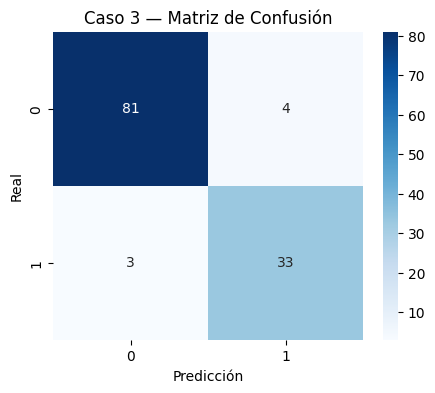

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 


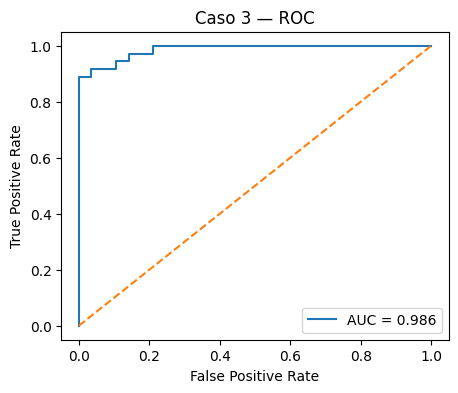

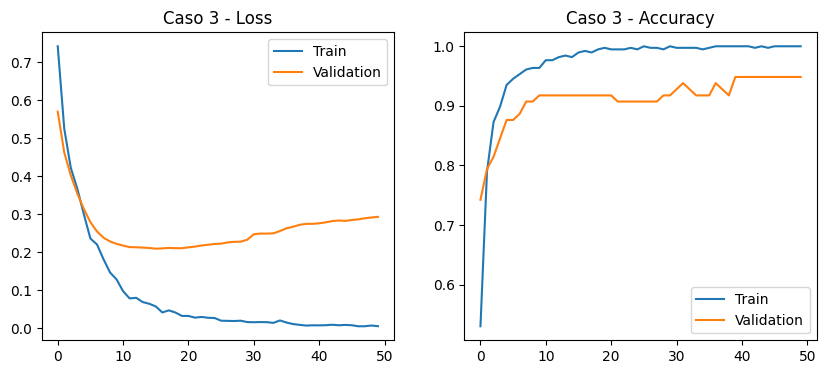

In [ ]:
#CASO 3: Optimización de hiperparámetros con Validación cruzada

kf = KFold(n_splits=5, shuffle=True, random_state=42)       # Se establece el trabajo con 5 folds (ya que son mas de 600 datos para trabajar)

def build_model_cv():
    model = Sequential([
        Input(shape=(X_train.shape[1],)),
        Dense(64, activation="relu"),                        # Se construye un modelo con 64 y 32 neuronas para mayor capacidad de aprendizaje
        Dense(32, activation="relu"),
        Dropout(0.3),                                        # Dropout para evitar sobreajuste
        Dense(1, activation="sigmoid")
    ])
    model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
    return model

model3 = build_model_cv()

# Entrenamiento final
history3 = model3.fit(
    X_train, y_train,
    epochs=50, batch_size=32,
    validation_split=0.2,
    verbose=0
)

y_pred3 = (model3.predict(X_test) > 0.5).astype(int)
cm3 = confusion_matrix(y_test, y_pred3)

plot_confusion_matrix(cm3, "Caso 3 — Matriz de Confusión")
acc3, sens3, esp3, vpp3, vpn3 = compute_metrics(cm3)
plot_roc_curve(y_test, model3.predict(X_test), "Caso 3 — ROC")
plot_history(history3, "Caso 3")


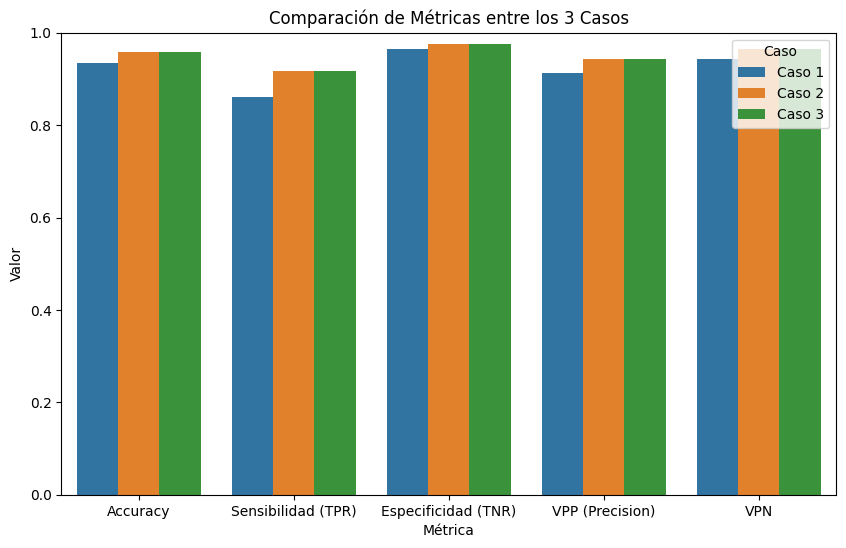

Accuracy 1: 0.9338842975206612
Accuracy 2: 0.9586776859504132
Accuracy 3: 0.9586776859504132
Sensibilidad 1: 0.8611111111111112
Sensibilidad 2: 0.9166666666666666
Sensibilidad 3: 0.9166666666666666
Especificidad 1: 0.9647058823529412
Especificidad 2: 0.9764705882352941
Especificidad 3: 0.9764705882352941
VPP 1: 0.9117647058823529
VPP 2: 0.9428571428571428
VPP 3: 0.9428571428571428
VPN 1: 0.9425287356321839
VPN 2: 0.9651162790697675
VPN 3: 0.9651162790697675


In [ ]:
# 🔵 Comparación de métricas entre los 3 casos

metrics_df = pd.DataFrame({
    "Caso": ["Caso 1", "Caso 2", "Caso 3"],
    "Accuracy": [acc1, acc2, acc3],
    "Sensibilidad (TPR)": [sens1, sens2, sens3],
    "Especificidad (TNR)": [esp1, esp2, esp3],
    "VPP (Precision)": [vpp1, vpp2, vpp3],
    "VPN": [vpn1, vpn2, vpn3]
})

# Gráfico de barras comparativo
metrics_df_melted = metrics_df.melt(id_vars="Caso", var_name="Métrica", value_name="Valor")

plt.figure(figsize=(10,6))
sns.barplot(data=metrics_df_melted, x="Métrica", y="Valor", hue="Caso")
plt.ylim(0,1)
plt.title("Comparación de Métricas entre los 3 Casos")
plt.ylabel("Valor")
plt.show()

print("Accuracy 1:", acc1)
print("Accuracy 2:", acc2)
print("Accuracy 3:", acc3)
print("Sensibilidad 1:", sens1)
print("Sensibilidad 2:", sens2)
print("Sensibilidad 3:", sens3)
print("Especificidad 1:", esp1)
print("Especificidad 2:", esp2)
print("Especificidad 3:", esp3)
print("VPP 1:", vpp1)
print("VPP 2:", vpp2)
print("VPP 3:", vpp3)
print("VPN 1:", vpn1)
print("VPN 2:", vpn2)
print("VPN 3:", vpn3)

